# 04 · Evaluation protocols, ablation, error analysis  *(owner: Sumayya)*

| Protocol | Split rule | What it tests |
|---|---|---|
| **Unseen-subject** | leave-one-subject-out (LOSO) | generalisation to new people (the realistic one) |
| **Seen-subject, time-blocked** | each video cut into 2-minute blocks; blocks are held out | participant-dependent: the same person AND the same state are in training |
| **Seen-subject, video held out** | whole videos held out (5-fold) | same person, but never the same video, so their *other* states are in training (a harder, odd setting) |
| **Ablation** | subject-grouped 5-fold | contribution of each feature group |

Baselines: majority class, PERCLOS-only logistic regression. Window-level accuracy / macro-P / R / F1, **video-level accuracy** (majority vote and mean probability), 95% CIs from bootstrapping **subjects**, and **paired** comparisons between models (a difference counts only if its CI excludes 0).

**Speed switches (first code cell).** `LOSO=False, RUN_SEEN=False, RUN_ABLATION=False` gives a fast run (~minutes) that is good for *comparing calibration/window settings*; run everything (`True`) only for the final configuration. Results go to `results/<calibration>_w<window>/`, so runs never overwrite each other.

**Caveats to state in the report:** hyperparameters were tuned on folds 0-3 (notebook 03), so LOSO results for those subjects are very slightly optimistic; the time-blocked protocol has a small overlap at block boundaries (windows overlap by 50%).

In [1]:
import os, json, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from drowsy_utils import *

QUICK        = True   # tiny models; only to check that the notebook runs
LOSO         = True    # True: leave-one-subject-out (60 folds).  False: subject-grouped 10-fold (much faster)
RUN_SEEN     = True    # seen-subject protocols
RUN_ABLATION = True    # feature-group ablation
N_JOBS       = 3       # parallel folds. Lower to 2 if RAM is tight.
SEED         = 0

info = json.load(open("data/run_info.json")) if os.path.exists("data/run_info.json") else {}
RUN = f'{info.get("calibration", "unknown")}_w{int(info.get("win_s", 0))}' + ("" if (LOSO and not QUICK) else "_fast")
RES = f"results/{RUN}"; os.makedirs(RES, exist_ok=True)
print("run:", RUN, "| settings from notebook 02:", info)

df, groups = load_windows()
params = json.load(open("data/best_params.json")) if os.path.exists("data/best_params.json") else None
print("tuned params found" if params else "WARNING: no best_params.json - using defaults")
FEATS = feature_list(groups, list(groups))
X, y, subj, vid = df[FEATS], df.y.values, df.subject.values, df.video.values
models = make_models(params, quick=QUICK, seed=SEED)
unseen_cv = GroupKFold(5) if QUICK else (LeaveOneGroupOut() if LOSO else GroupKFold(10))
print(f"{len(df)} windows | {df.subject.nunique()} subjects | {df.video.nunique()} videos | unseen CV: {type(unseen_cv).__name__}")

run: subject_alert_w30_fast | settings from notebook 02: {'calibration': 'subject_alert', 'win_s': 30.0, 'step_s': 15.0, 'blink_thr': 0.8, 'closed_thrs': [0.5, 0.7, 0.8, 0.9]}
tuned params found
7223 windows | 60 subjects | 180 videos | unseen CV: GroupKFold


## 1 · Unseen-subject protocol + baselines

In [2]:
res_unseen = {}

maj = np.bincount(y).argmax(); P = np.zeros((len(y), 3)); P[:, maj] = 1
res_unseen["majority class"] = P                                       # baseline 1

perclos = [c for c in FEATS if c.startswith("perclos")]
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
res_unseen["PERCLOS-only LogReg"] = cv_proba(lr, df[perclos], y, subj, unseen_cv, N_JOBS)   # baseline 2

for name, m in models.items():
    print("running", name, "...", flush=True)
    res_unseen[name] = cv_proba(m, X, y, subj, unseen_cv, N_JOBS)

tab_unseen = summarize(res_unseen, df, "unseen-subject")
tab_unseen.round(3)

running rf ...
running xgb ...
running mlp ...
running ensemble ...


,protocol,model,accuracy,acc_ci95,macro_precision,macro_recall,macro_f1,video_acc_vote,video_acc_meanproba
0,unseen-subject,majority class,0.338,"[0.329, 0.347]",0.113,0.333,0.168,0.333,0.333
1,unseen-subject,PERCLOS-only LogReg,0.479,"[0.442, 0.515]",0.498,0.480,0.463,0.494,0.517
2,unseen-subject,rf,0.604,"[0.562, 0.642]",0.594,0.605,0.596,0.650,0.667
3,unseen-subject,xgb,0.579,"[0.540, 0.617]",0.565,0.580,0.567,0.628,0.628
4,unseen-subject,mlp,0.609,"[0.576, 0.640]",0.597,0.610,0.601,0.667,0.667
5,unseen-subject,ensemble,0.615,"[0.578, 0.648]",0.601,0.616,0.604,0.639,0.656


### Is a difference real?
Paired comparison on the same windows, resampling **subjects**. If the 95% interval contains 0, the data do not support a difference.

In [3]:
pred = {k: v.argmax(1) for k, v in res_unseen.items()}
pairs = [("ensemble", "PERCLOS-only LogReg"), ("xgb", "PERCLOS-only LogReg"), ("rf", "PERCLOS-only LogReg"),
         ("ensemble", "xgb"), ("ensemble", "rf"), ("ensemble", "mlp")]
rows = []
for a, b in pairs:
    d, lo, hi = paired_subject_bootstrap(df, pred[a], pred[b])
    rows.append(dict(comparison=f"{a}  minus  {b}", acc_diff=round(d, 3), ci95=f"[{lo:+.3f}, {hi:+.3f}]", supported=(lo > 0 or hi < 0)))
paired = pd.DataFrame(rows); paired.to_csv(f"{RES}/paired_comparisons.csv", index=False); paired

,comparison,acc_diff,ci95,supported
0,ensemble minus PERCLOS-only LogReg,0.136,"[+0.096, +0.177]",True
1,xgb minus PERCLOS-only LogReg,0.100,"[+0.060, +0.142]",True
2,rf minus PERCLOS-only LogReg,0.125,"[+0.091, +0.162]",True
3,ensemble minus xgb,0.036,"[+0.011, +0.063]",True
4,ensemble minus rf,0.011,"[-0.013, +0.034]",False
5,ensemble minus mlp,0.006,"[-0.007, +0.018]",False


## 2 · Seen-subject protocols

In [4]:
res_seen = {}
if RUN_SEEN:
    # (a) time-blocked: every video is cut into 2-minute blocks and blocks are the CV groups
    blk = (df["t_start"] // 120).astype(int).astype(str)
    grp_block = pd.Series(vid).astype(str).values + "_b" + blk.values
    res_block = {}
    for name, m in models.items():
        print("seen (time-blocked):", name, flush=True)
        res_block[name] = cv_proba(m, X, y, grp_block, GroupKFold(5), N_JOBS)
    # (b) whole videos held out
    res_video = {}
    for name, m in models.items():
        print("seen (video held out):", name, flush=True)
        res_video[name] = cv_proba(m, X, y, vid, GroupKFold(5), N_JOBS)
    res_seen = {"block": res_block, "video": res_video}
    tabs = [tab_unseen, summarize(res_block, df, "seen-subject (time-blocked)"), summarize(res_video, df, "seen-subject (video held out)")]
else:
    tabs = [tab_unseen]
tab_all = pd.concat(tabs, ignore_index=True)
tab_all.to_csv(f"{RES}/main_results.csv", index=False)
tab_all.round(3)

seen (time-blocked): rf
seen (time-blocked): xgb
seen (time-blocked): mlp
seen (time-blocked): ensemble
seen (video held out): rf
seen (video held out): xgb
seen (video held out): mlp
seen (video held out): ensemble


,protocol,model,accuracy,acc_ci95,macro_precision,macro_recall,macro_f1,video_acc_vote,video_acc_meanproba
0,unseen-subject,majority class,0.338,"[0.329, 0.347]",0.113,0.333,0.168,0.333,0.333
1,unseen-subject,PERCLOS-only LogReg,0.479,"[0.442, 0.515]",0.498,0.480,0.463,0.494,0.517
2,unseen-subject,rf,0.604,"[0.562, 0.642]",0.594,0.605,0.596,0.650,0.667
3,unseen-subject,xgb,0.579,"[0.540, 0.617]",0.565,0.580,0.567,0.628,0.628
4,unseen-subject,mlp,0.609,"[0.576, 0.640]",0.597,0.610,0.601,0.667,0.667
5,unseen-subject,ensemble,0.615,"[0.578, 0.648]",0.601,0.616,0.604,0.639,0.656
6,seen-subject (time-blocked),rf,0.717,"[0.683, 0.750]",0.714,0.717,0.713,0.794,0.811
7,seen-subject (time-blocked),xgb,0.641,"[0.603, 0.677]",0.633,0.642,0.633,0.689,0.711
8,seen-subject (time-blocked),mlp,0.716,"[0.686, 0.746]",0.713,0.717,0.713,0.811,0.811
9,seen-subject (time-blocked),ensemble,0.732,"[0.698, 0.764]",0.729,0.732,0.728,0.822,0.817


In [5]:
cmp = tab_all[tab_all.model.isin(["rf", "xgb", "mlp", "ensemble"])].pivot(index="model", columns="protocol", values="macro_f1")
cmp.round(3)

protocol,seen-subject (time-blocked),seen-subject (video held out),unseen-subject
model,,,
ensemble,0.728,0.538,0.604
mlp,0.713,0.535,0.601
rf,0.713,0.546,0.596
xgb,0.633,0.515,0.567


## 3 · Confusion matrices (ensemble)

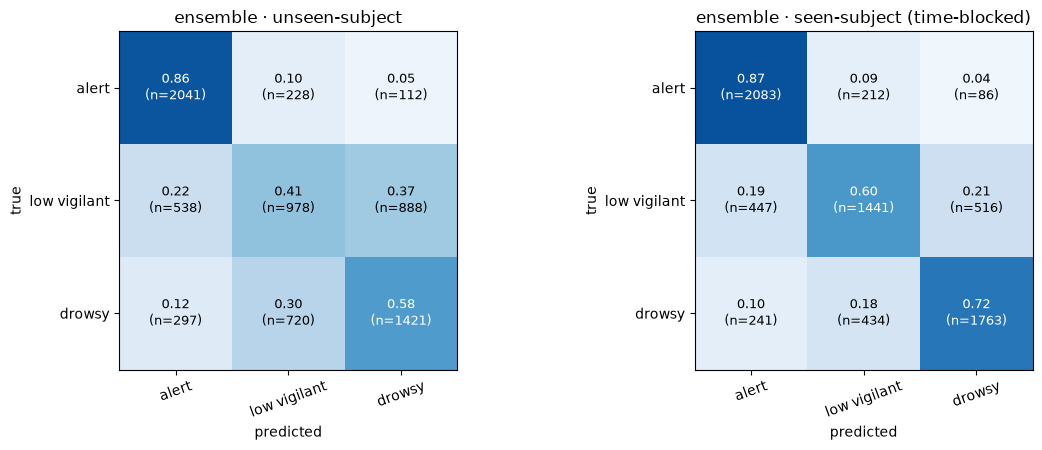

              precision    recall  f1-score   support

       alert      0.710     0.857     0.776      2381
low vigilant      0.508     0.407     0.452      2404
      drowsy      0.587     0.583     0.585      2438

    accuracy                          0.615      7223
   macro avg      0.601     0.616     0.604      7223
weighted avg      0.601     0.615     0.604      7223



In [6]:
n_pan = 2 if RUN_SEEN else 1
fig, ax = plt.subplots(1, n_pan, figsize=(6 * n_pan, 4.6), squeeze=False); ax = ax[0]
cm_u = plot_cm(y, res_unseen["ensemble"].argmax(1), ax[0], "ensemble · unseen-subject")
if RUN_SEEN:
    plot_cm(y, res_seen["block"]["ensemble"].argmax(1), ax[1], "ensemble · seen-subject (time-blocked)")
plt.tight_layout(); plt.savefig(f"{RES}/confusion_matrices.png", dpi=150); plt.show()
print(classification_report(y, res_unseen["ensemble"].argmax(1), target_names=LABEL_NAMES, digits=3))

## 4 · Feature-group ablation
Each group alone, and the full set with one group removed (subject-grouped 5-fold; the ensemble is re-trained every time). Differences smaller than the CIs above are not evidence.

ablation: all features
ablation: only eye
ablation: without eye
ablation: only mouth
ablation: without mouth
ablation: only head
ablation: without head
ablation: only brow
ablation: without brow


,n_features,accuracy,macro_f1,video_acc_vote
config,,,,
only mouth,5,0.477,0.453,0.522
only brow,2,0.501,0.472,0.539
only head,7,0.523,0.507,0.550
only eye,14,0.536,0.528,0.606
without head,21,0.573,0.560,0.594
without brow,26,0.589,0.577,0.628
without mouth,23,0.598,0.588,0.611
all features,28,0.615,0.604,0.639
without eye,14,0.633,0.625,0.694


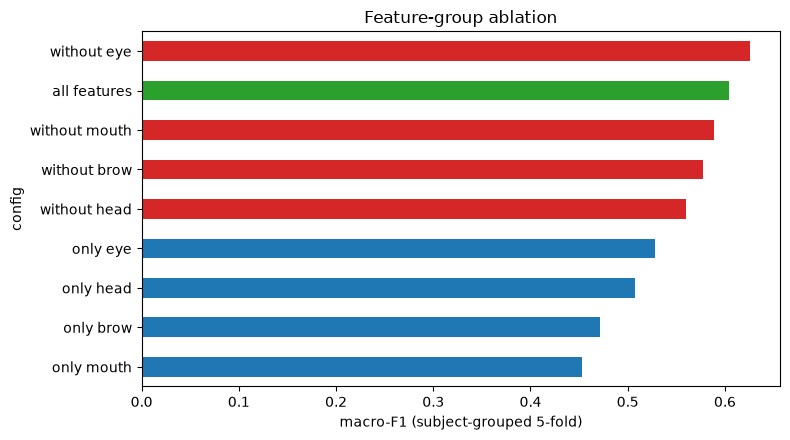

In [7]:
if RUN_ABLATION:
    abl_cv = GroupKFold(5)
    configs = {"all features": list(groups)}
    for g in groups:
        configs[f"only {g}"] = [g]
        configs[f"without {g}"] = [x for x in groups if x != g]
    rows = []
    for cname, gs in configs.items():
        print("ablation:", cname, flush=True)
        cols = feature_list(groups, gs)
        P = cv_proba(models["ensemble"], df[cols], y, subj, abl_cv, N_JOBS)
        r = window_metrics(y, P.argmax(1)); r.update(video_level(df, P)); r.update(config=cname, n_features=len(cols))
        rows.append(r)
    abl = pd.DataFrame(rows).set_index("config").sort_values("macro_f1")
    abl.to_csv(f"{RES}/ablation.csv")
    display(abl[["n_features", "accuracy", "macro_f1", "video_acc_vote"]].round(3))
    ax = abl["macro_f1"].plot.barh(figsize=(8, 4.5), color=["C3" if c.startswith("without") else "C0" if c.startswith("only") else "C2" for c in abl.index])
    ax.set_xlabel("macro-F1 (subject-grouped 5-fold)"); ax.set_title("Feature-group ablation"); plt.tight_layout()
    plt.savefig(f"{RES}/ablation.png", dpi=150); plt.show()
else:
    print("RUN_ABLATION = False - skipped")

## 5 · Error analysis
Where does the ensemble fail: which subjects, which class boundary, and (optionally) which subgroups?

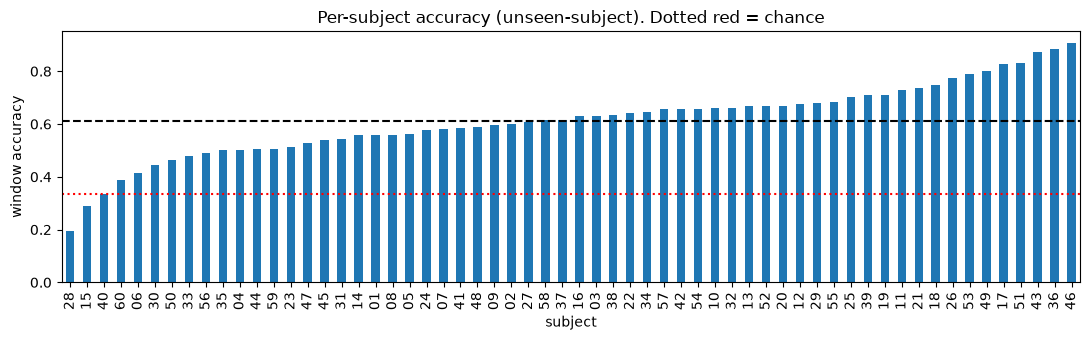

Hardest subjects:
 subject
28    0.195
15    0.289
40    0.333
60    0.390
06    0.415
30    0.445
50    0.465
33    0.478

Subjects BELOW chance (< 0.25): 1 of 60  <- systematically wrong, not just noisy

alert recalled correctly:   0.86
low  -> predicted alert:    0.22 | low -> drowsy: 0.37
drowsy -> predicted low:    0.30   (the fuzzy boundary is usually here)


In [8]:
pred_e = res_unseen["ensemble"].argmax(1)
per_subj = df.assign(correct=(pred_e == y)).groupby("subject").correct.mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 3.5)); per_subj.plot.bar(ax=ax)
ax.axhline(per_subj.mean(), ls="--", c="k"); ax.axhline(1 / 3, ls=":", c="r"); ax.set_ylabel("window accuracy")
ax.set_title("Per-subject accuracy (unseen-subject). Dotted red = chance")
plt.tight_layout(); plt.savefig(f"{RES}/per_subject.png", dpi=150); plt.show()
print("Hardest subjects:\n", per_subj.head(8).round(3).to_string())
print(f"\nSubjects BELOW chance (< 0.25): {(per_subj < 0.25).sum()} of {len(per_subj)}  <- systematically wrong, not just noisy")

cmn = cm_u / cm_u.sum(1, keepdims=True)
print(f"\nalert recalled correctly:   {cmn[0,0]:.2f}")
print(f"low  -> predicted alert:    {cmn[1,0]:.2f} | low -> drowsy: {cmn[1,2]:.2f}")
print(f"drowsy -> predicted low:    {cmn[2,1]:.2f}   (the fuzzy boundary is usually here)")

In [9]:
# OPTIONAL subgroup analysis (e.g. glasses). Create data/subject_metadata.csv with columns:
#   subject,glasses          (subject ids exactly as in windows.csv, e.g. 01, 02, ...; glasses = 0/1)
meta_path = "data/subject_metadata.csv"
if os.path.exists(meta_path):
    meta = pd.read_csv(meta_path, dtype={"subject": str})
    d = df.assign(correct=(pred_e == y)).merge(meta, on="subject", how="left")
    for col in [c for c in meta.columns if c != "subject"]:
        print(d.groupby(col).correct.agg(["mean", "count"]).round(3).rename(columns={"mean": "accuracy"}), "\n")
else:
    print("No data/subject_metadata.csv - skipping subgroup analysis.")

No data/subject_metadata.csv - skipping subgroup analysis.


In [10]:
# Worst windows: confidently wrong. If many show perclos_80 = 1.0 for a whole window, the eyes look "closed" only because
# the subject's baseline is off (calibration problem), not because they are drowsy.
err = df.assign(pred=pred_e, p_true=res_unseen["ensemble"][np.arange(len(df)), y])
cols = ["subject", "label", "t_start", "pred", "p_true", "perclos_80", "blink_dur_mean", "n_yawns"]
err[err.pred != err.y].sort_values("p_true").head(10)[cols].round(3)

,subject,label,t_start,pred,p_true,perclos_80,blink_dur_mean,n_yawns
3553,31,alert,135.0,2,0.069,0.357,0.282,0
3644,31,low,210.0,2,0.072,0.920,4.605,0
3552,31,alert,120.0,2,0.073,0.299,0.345,0
3551,31,alert,105.0,2,0.074,0.299,0.320,0
3643,31,low,195.0,2,0.077,0.715,0.859,0
2230,20,alert,255.0,2,0.077,0.815,0.842,0
3641,31,low,165.0,2,0.077,0.816,1.629,0
2228,20,alert,225.0,2,0.078,0.684,0.894,0
2229,20,alert,240.0,2,0.079,0.753,1.327,0
2238,20,alert,375.0,2,0.081,0.844,3.613,0


## 6 · Compare runs (calibration / window settings)
After running notebooks 02 → 04 for several settings, this table puts the unseen-subject results side by side.

In [11]:
runs = []
for f in sorted(glob.glob("results/*/main_results.csv")):
    t = pd.read_csv(f); t["run"] = os.path.basename(os.path.dirname(f)); runs.append(t)
if runs:
    allr = pd.concat(runs)
    sel = allr[(allr.protocol == "unseen-subject") & allr.model.isin(["PERCLOS-only LogReg", "rf", "xgb", "ensemble"])]
    display(sel.pivot(index="run", columns="model", values="macro_f1").round(3))
    display(sel[sel.model == "ensemble"].set_index("run")[["accuracy", "acc_ci95", "video_acc_vote"]].round(3))

model,PERCLOS-only LogReg,ensemble,rf,xgb
run,,,,
none_w30,0.397,0.436,0.445,0.433
none_w30_fast,0.387,0.439,0.445,0.427
per_video_w30,0.423,0.451,0.464,0.460
per_video_w30_fast,0.421,0.453,0.469,0.450
subject_alert_w30,0.456,0.597,0.581,0.593
subject_alert_w30_fast,0.463,0.604,0.596,0.567
subject_all_w30,0.410,0.451,0.451,0.469
subject_all_w30_fast,0.409,0.457,0.452,0.466
subject_all_w30_first,0.410,0.451,0.451,0.469


,accuracy,acc_ci95,video_acc_vote
run,,,
none_w30,0.443,"[0.404, 0.481]",0.478
none_w30_fast,0.446,"[0.410, 0.483]",0.494
per_video_w30,0.460,"[0.424, 0.495]",0.478
per_video_w30_fast,0.464,"[0.426, 0.500]",0.494
subject_alert_w30,0.607,"[0.567, 0.647]",0.644
subject_alert_w30_fast,0.615,"[0.578, 0.648]",0.639
subject_all_w30,0.454,"[0.407, 0.497]",0.472
subject_all_w30_fast,0.460,"[0.413, 0.502]",0.461
subject_all_w30_first,0.454,"[0.407, 0.497]",0.472


## Hand-off to the report
Tables and figures are in `results/<run>/`: `main_results.csv`, `paired_comparisons.csv`, `ablation.csv`, `confusion_matrices.png`, `ablation.png`, `per_subject.png`.